In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle
import random
random.seed(42)

In [2]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
phylo_score = pickle.load(open("data/eval_phyloscore.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [3]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)

In [4]:
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for hyper in extract_hyperparameters(dict):
        score = 0
        for dataset in train_set:
            score += dict[(dataset, *hyper)][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = hyper
    return best_hyperparameters

In [5]:
best_hyper(phylo_score, datasets)

('0.5', '0.01', 'optdiff', 'APC')

In [6]:
def cross_validation(data, per_dataset_results : dict, selected_hyper : set, splits=5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(data, train)
        selected_hyper.add(best_hyperparameters)
        for dataset in test:
            results.append(data[(dataset, *best_hyperparameters)][1])
            if dataset not in per_dataset_results:
                per_dataset_results[dataset] = []
            per_dataset_results[dataset].append(data[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results) * 100

In [7]:
rscape_per_dataset = {}
rscape_hyperparameters = set()
phylo_score_per_dataset = {}
phylo_score_hyperparameters = set()
results_rscape = [cross_validation(r_scape, rscape_per_dataset, rscape_hyperparameters) for _ in range(1)]
results_phyloscore = [cross_validation(phylo_score, phylo_score_per_dataset, phylo_score_hyperparameters) for _ in range(1000)]

In [8]:
phylo_score_hyperparameters

for hyper in phylo_score_hyperparameters:
    print(hyper, np.mean([phylo_score[(dataset, *hyper)][1] for dataset in datasets]))

('1.0', '0.01', 'optdiff', 'APC') 0.7128661672802584
('0.5', '0.0', 'optdiff', 'ASC') 0.7144999201961562
('0.5', '0.0', 'optdiff', 'APC') 0.7144816947132968
('0.5', '0.01', 'optdiff', 'ASC') 0.7146693245978758
('1.0', '0.0', 'optdiff', 'APC') 0.7127192504916801
('0.5', '0.01', 'optdiff', 'APC') 0.7147547542939079
('0.5', '0.1', 'optdiff', 'ASC') 0.7144880704922469
('0.5', '0.1', 'optdiff', 'APC') 0.7146611305435817
('1.0', '0.01', 'optdiff', 'ASC') 0.7136479175578238
('1.0', '1.0', 'optdiff', 'APC') 0.712394760877221


In [9]:
def plot_side_by_side_barplot(dict1, dict2, label1='Dataset 1', label2='Dataset 2', 
                               error_type='std', figsize=(12, 6)):
    """
    Create side-by-side bar plot comparing two dictionaries.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with keys as categories and values as lists of floats
    label1, label2 : str
        Labels for the two datasets
    figsize : tuple
        Figure size (width, height)
    """
    # Get common categories (keys present in both dictionaries)
    categories = sorted(set(dict1.keys()) | set(dict2.keys()))
    
    # Calculate statistics for dict1
    means1 = []
    errors1 = []
    for cat in categories:
        data = dict1[cat]
        means1.append(np.mean(data))
        errors1.append(np.std(data))
    
    means2 = []
    errors2 = []
    for cat in categories:
        data = dict2[cat]
        means2.append(np.mean(data))
        errors2.append(np.std(data))    
    
    
    # Create plot
    x = np.arange(len(categories))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bars
    bars1 = ax.bar(x - width/2, means1, width, yerr=errors1, 
                   capsize=2, label=label1, color='skyblue', 
                   edgecolor='black', alpha=0.7)
                   
    bars2 = ax.bar(x + width/2, means2, width, yerr=errors2, 
                   capsize=2, label=label2, color='red', 
                   edgecolor='black', alpha=0.7)
    
    # Customize plot
    ax.set_xlabel('Categories', fontsize=12)
    ax.set_ylabel('Values', fontsize=12)
    ax.set_title(f'Side-by-Side Comparison: {label1} vs {label2}', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=90)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig, ax

In [10]:
def scatter_compare_with_diagonal(dict1, dict2, label1='Dataset 1', label2='Dataset 2',
                                   error_type='sem', figsize=(8, 8)):
    """
    Create scatter plot comparing two dictionaries with diagonal line.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with same keys and lists of floats as values
    label1, label2 : str
        Labels for axes
    error_type : str or None
        'std', 'sem', 'ci95', or None for error bars
    figsize : tuple
        Figure size (square recommended)
    """
    # Get common categories
    common_keys = sorted(set(dict1.keys()) & set(dict2.keys()))
    
    if not common_keys:
        raise ValueError("Dictionaries have no common keys")
    
    # Calculate means and errors
    medians1 = []
    medians2 = []
    errors1 = []
    errors2 = []
    
    for key in common_keys:
        data1 = dict1[key]
        data2 = dict2[key]
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        medians1.append(median1)
        medians2.append(median2)
        
        if error_type == 'std':
            errors1.append(np.std(data1))
            errors2.append(np.std(data2))
        elif error_type == 'minmax':
            errors1.append([np.abs(np.median(data1) - np.min(data1)), np.abs(np.max(data1) - np.median(data1))])
            errors2.append([np.abs(np.median(data2) - np.min(data2)), np.abs(np.max(data2) - np.median(data2))])
        elif error_type == 'ci95':
            sem1 = np.std(data1) / np.sqrt(len(data1))
            sem2 = np.std(data2) / np.sqrt(len(data2))
            errors1.append(sem1 * 1.96)
            errors2.append(sem2 * 1.96)
        else:
            errors1.append(0)
            errors2.append(0)
    
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add diagonal line (y=x)
    min_val = 0
    max_val = 1
    ax.plot([min_val, max_val], 
            [min_val, max_val], 
            'k--', alpha=0.5)
    
    # Add error bars (horizontal and vertical)
    if error_type:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   fmt='o', capsize=3, capthick=1, elinewidth=1,
                   color='blue', alpha=0.7, markersize=2,
                   label=f'{label1} vs {label2}')
    else:
        ax.scatter(medians1, medians2, color='blue', alpha=0.7, s=80,
                  label=f'{label1} vs {label2}')
    
    # Customize plot
    ax.set_xlabel(f'{label1} (Average Precision)', fontsize=12)
    ax.set_ylabel(f'{label2} (Average Precision)', fontsize=12)
    ax.set_title(f'Scatter Plot Comparison: {label1} vs {label2}', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_aspect('equal')
    
    plt.tight_layout()
    return fig, ax

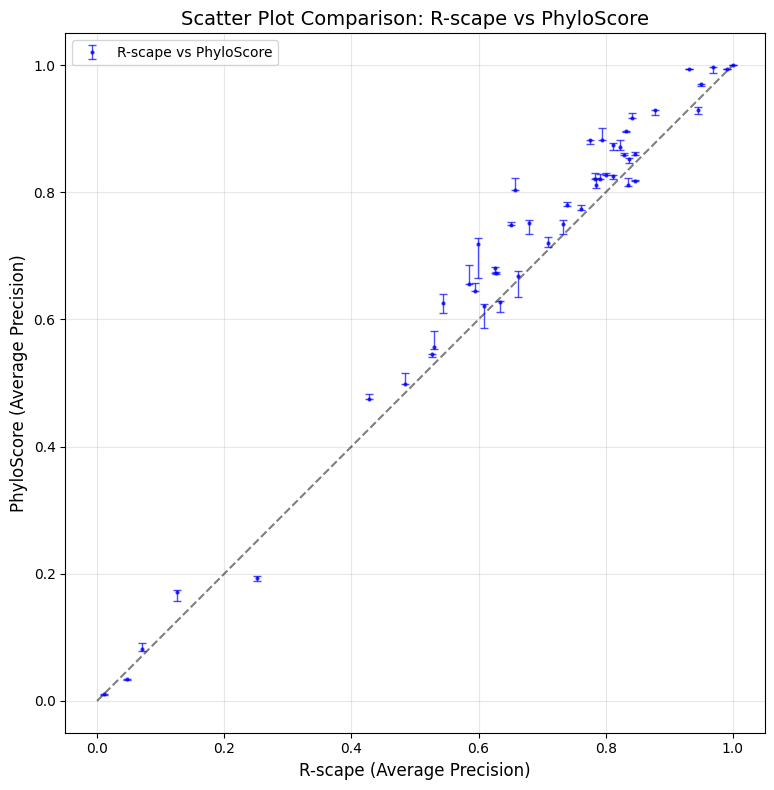

In [18]:
fig, _ =scatter_compare_with_diagonal(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore', error_type='minmax')
fig.savefig("cross_validation_scatter.pdf")

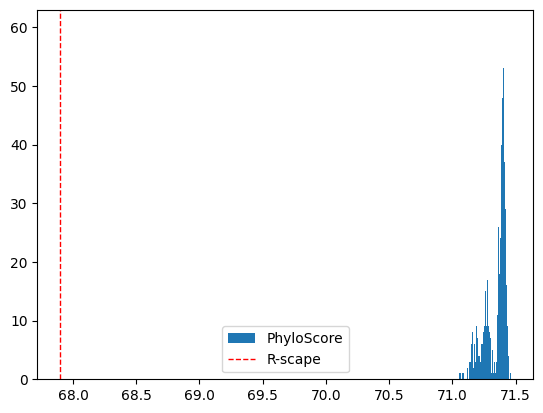

In [16]:
plt.hist(results_phyloscore, bins=100, label='PhyloScore')
#plot a line where rscape performance is
plt.axvline(np.mean(results_rscape), color='red', linestyle='dashed', linewidth=1, label='R-scape')
plt.legend()
plt.savefig("cross_validation_results.pdf")

In [13]:
all_hyper = extract_hyperparameters(phylo_score)

In [51]:
def plot_variation_per_hyperparameter(phylo_score):
    all_hyper = extract_hyperparameters(phylo_score)
    num_types = len(next(iter(all_hyper)))
    
    # Create a 2x2 grid of subplots
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    # Flatten axes for easy indexing (optional)
    axes = axes.flatten()
    
    str_types = ["lambda", "lambda_MI", "score type", "correction type"]
    
    for type in range(num_types):
        hyperparameters = sorted(list(set(h[type] for h in all_hyper)), key=lambda x: float(x) if x.replace('.', '', 1).isdigit() else x)
        means = []
        for hyper in hyperparameters:
            values = [phylo_score[(dataset, *h)][1] for dataset in datasets for h in all_hyper if h[type] == hyper]
            mean = np.mean(values)
            means.append(mean)
            print(f"Type {type}, Hyperparameter {hyper}: Mean AP = {mean:.4f}")
        axes[type].bar(list(hyperparameters), means)
        axes[type].set_ylabel('Marginalized Average Precision over all families')
        axes[type].set_ylim(0.6, 0.72)
        axes[type].set_title(f'Effect of {str_types[type]}')
        axes[type].set_xticklabels(hyperparameters, rotation=90)
    plt.tight_layout()
    plt.savefig("hyperparameter_variation.pdf")
    plt.show()
    

Type 0, Hyperparameter 0.05: Mean AP = 0.6680
Type 0, Hyperparameter 0.1: Mean AP = 0.6755
Type 0, Hyperparameter 0.25: Mean AP = 0.6899
Type 0, Hyperparameter 0.5: Mean AP = 0.6999
Type 0, Hyperparameter 1.0: Mean AP = 0.7016
Type 0, Hyperparameter 2.5: Mean AP = 0.6790
Type 0, Hyperparameter 5.0: Mean AP = 0.6421
Type 1, Hyperparameter 0.0: Mean AP = 0.6822
Type 1, Hyperparameter 0.01: Mean AP = 0.6823
Type 1, Hyperparameter 0.1: Mean AP = 0.6822
Type 1, Hyperparameter 1.0: Mean AP = 0.6810
Type 1, Hyperparameter 10.0: Mean AP = 0.6695
Type 2, Hyperparameter lldiff: Mean AP = 0.6827
Type 2, Hyperparameter optdiff: Mean AP = 0.6762
Type 3, Hyperparameter APC: Mean AP = 0.6975
Type 3, Hyperparameter ASC: Mean AP = 0.6978
Type 3, Hyperparameter None: Mean AP = 0.6431


/tmp/ipykernel_159174/1625798022.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_159174/1625798022.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_159174/1625798022.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_159174/1625798022.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)


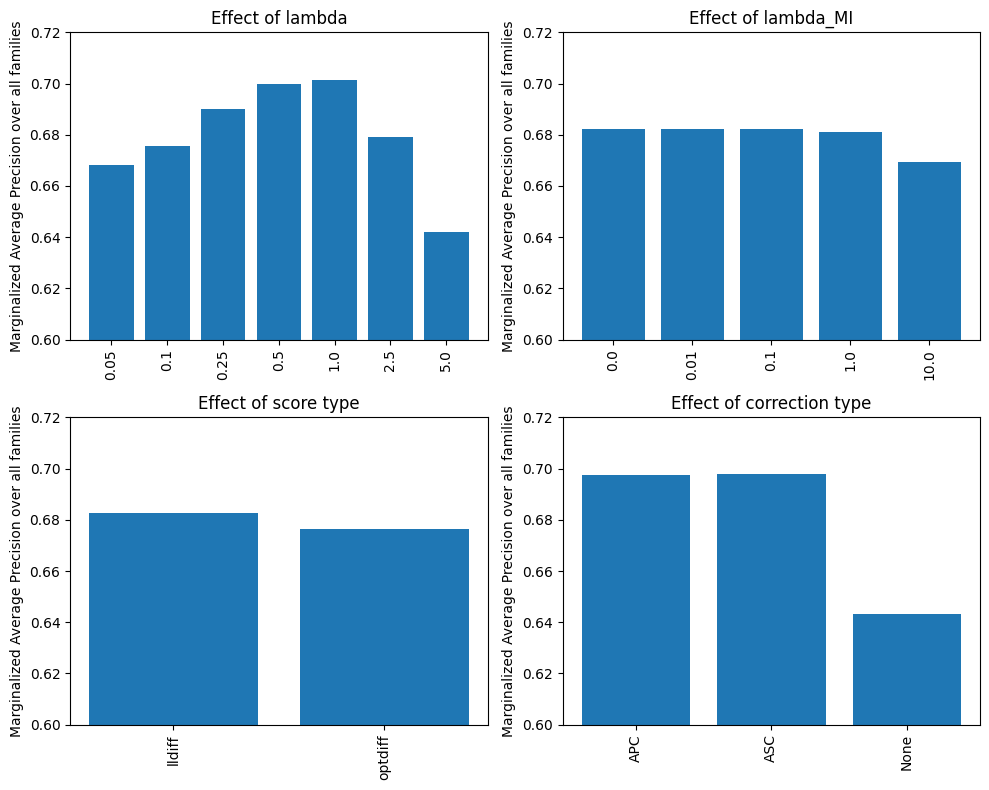

In [53]:
plot_variation_per_hyperparameter(phylo_score)